In [92]:
import torch
import torch.nn as nn
import sklearn

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size_1, hidden_size_2, output_size):
        """
        初始化多层感知机

        参数:
            input_size:  输入特征维度
            hidden_size: 隐藏层神经元数量
            output_size: 输出维度
        """
        super(MLP, self).__init__()
        # TODO: 定义全连接层和激活函数
        self.fc1 = nn.Linear(input_size,hidden_size_1)      # 输入层 → 隐藏层
        self.fc2 = nn.Linear(hidden_size_1,hidden_size_2)
        self.fc3 = nn.Linear(hidden_size_2, output_size)# 隐藏层 → 输出层
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        self.tanh = nn.Tanh()

    def forward(self, x):
        """
        前向传播

        参数:
            x: 输入数据，形状为 (batch_size, input_size)

        返回:
            输出值，形状为 (batch_size, output_size)
        """
        # TODO: 补全前向传播过程
        x = self.relu(self.fc1(x))              # fc1 + relu
        x = self.relu(self.fc2(x))              # fc2 + relu
        x = self.sigmoid(self.fc3(x))
        return x

model = MLP(input_size=2, hidden_size_1=16, hidden_size_2=16, output_size=1)

print(model)

MLP(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
  (tanh): Tanh()
)


In [93]:
def generate_moon_data(n_samples=10000, noise=0.15, test_size=0.2):
    """
    生成双月数据集并划分训练/测试集

    返回:
        X_train, X_test, y_train, y_test (均为 numpy 数组)
    """
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split

    # TODO: 生成数据、标准化、划分训练/测试集
    from sklearn.preprocessing import StandardScaler

    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    X_train = torch.as_tensor(X_train, dtype=torch.float32)
    X_test = torch.as_tensor(X_test, dtype=torch.float)
    y_train = torch.as_tensor(y_train, dtype=torch.float32).reshape(-1, 1)
    y_test  = torch.as_tensor(y_test,  dtype=torch.float32).reshape(-1, 1)

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = generate_moon_data()

print(f"{X_train.shape}, {y_train.shape}, {X_test.shape}, {y_test.shape}")

torch.Size([8000, 2]), torch.Size([8000, 1]), torch.Size([2000, 2]), torch.Size([2000, 1])


In [94]:
# 设置超参数
learning_rate = 0.01
num_epochs = 1000
# 损失函数与优化器
criterion = nn.BCELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

print(criterion)
print(optimizer)

BCELoss()
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)


In [95]:
from sklearn.metrics import accuracy_score

In [96]:
# 构建训练循环
def train_model(model, X_train, X_test, y_train, y_test, num_epochs, criterion, optimizer):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(num_epochs):
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            p_tr, p_te = model(X_train), model(X_test)
            history["train_loss"].append(criterion(p_tr, y_train).item())
            history["test_loss"].append(criterion(p_te, y_test).item())
            history["train_acc"].append(
                ((p_tr >= 0.5).float() == y_train).float().mean().item())
            history["test_acc"].append(
                ((p_te >= 0.5).float() == y_test).float().mean().item())

    return model, history

model, history = train_model(model, X_train, X_test, y_train, y_test, num_epochs, criterion, optimizer)

In [97]:
import matplotlib.pyplot as plt

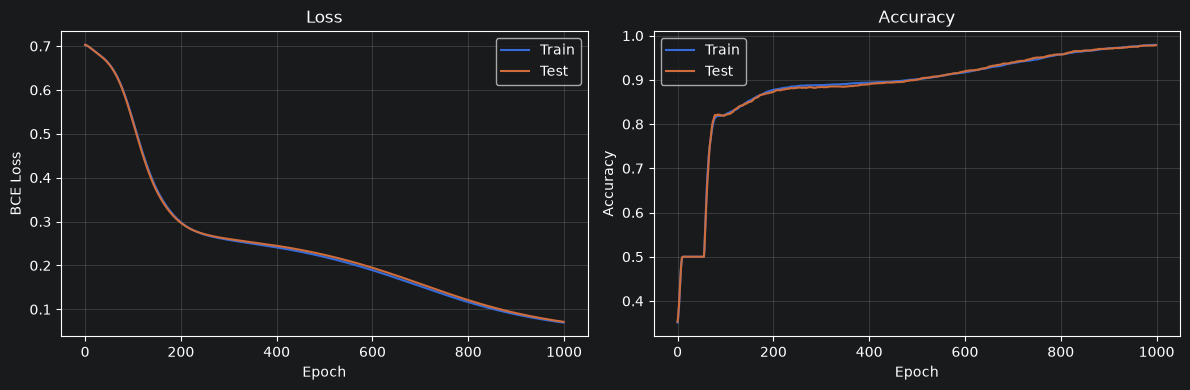

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["test_loss"],  label="Test")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["test_acc"],  label="Test")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig("loss_acc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

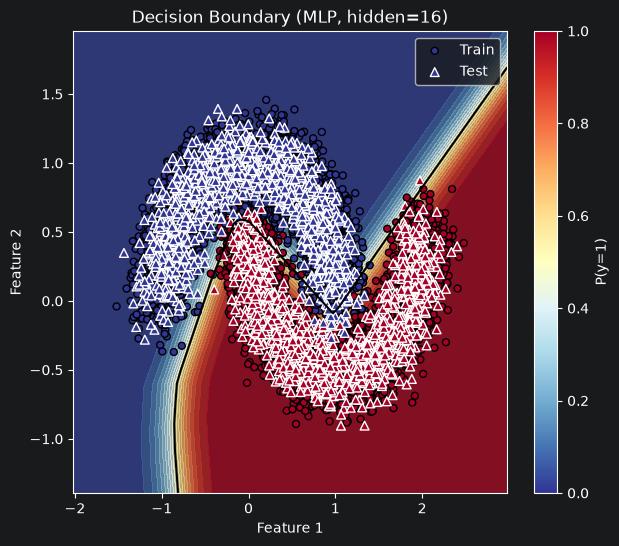

In [99]:
import numpy as np

x_min, x_max = X_train[:, 0].min().item(), X_train[:, 0].max().item()
y_min, y_max = X_train[:, 1].min().item(), X_train[:, 1].max().item()
pad = 0.5                                        # 留白，别让点贴边

xx, yy = np.meshgrid(np.linspace(x_min - pad, x_max + pad, 300),
                     np.linspace(y_min - pad, y_max + pad, 300))
grid = torch.as_tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

model.eval()
with torch.no_grad():
    zz = model(grid).numpy().reshape(xx.shape)   # 概率面

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, zz, levels=20, cmap="RdYlBu_r", alpha=0.7)
plt.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.5)

tr_x, tr_y = X_train.numpy(), y_train.numpy().ravel()
te_x, te_y = X_test.numpy(),  y_test.numpy().ravel()
plt.scatter(tr_x[:, 0], tr_x[:, 1], c=tr_y, cmap="RdYlBu_r",
            edgecolors="k", s=25, marker="o", label="Train")
plt.scatter(te_x[:, 0], te_x[:, 1], c=te_y, cmap="RdYlBu_r",
            edgecolors="w", s=40, marker="^", label="Test")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.title("Decision Boundary (MLP, hidden=16)")
plt.legend(); plt.colorbar(label="P(y=1)")
plt.show()

# 这个cell由deepseek完成